# NHTSA complaints & recalls: data exploration

**Source**: public NHTSA APIs (`api.nhtsa.gov`), fetched with `python -m nhtsa_quality_agent.data.ingest` and cleaned with `python -m nhtsa_quality_agent.data.clean`.

**Scope**: 6 models (Toyota Camry, Honda CR-V, Ford Explorer, Tesla Model 3, Jeep Grand Cherokee, Ram 1500), model years 2019-2023.

**Goal**: understand what the complaints look like before building the RAG (milestone 3) and the component classifier (milestone 5).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROCESSED = Path("../data/processed")

complaints = pd.read_parquet(PROCESSED / "complaints.parquet")
recalls = pd.read_parquet(PROCESSED / "recalls.parquet")
recall_vehicles = pd.read_parquet(PROCESSED / "recall_vehicles.parquet")

# Parquet list columns come back as numpy arrays: convert them to plain lists,
# otherwise `labels == [...]` compares element-wise and returns an array.
complaints["components"] = complaints["components"].map(list)

for name, df in [
    ("complaints", complaints),
    ("recalls", recalls),
    ("recall_vehicles", recall_vehicles),
]:
    print(f"{name:<16} {len(df):>6} rows")

complaints        14512 rows
recalls             191 rows
recall_vehicles     381 rows


In [2]:
complaints.dtypes

odi_number                  str
make                        str
model                       str
model_year                int64
date_filed       datetime64[us]
date_incident    datetime64[us]
crash                      bool
fire                       bool
injuries                  int64
deaths                    int64
components               object
summary                     str
vin                         str
dtype: object

In [3]:
# `components` must hold real lists (Parquet keeps them), not strings.
complaints[["odi_number", "make", "model", "model_year", "components"]].head()

,odi_number,make,model,model_year,components
0,11099262,ram,1500,2019,[SERVICE BRAKES]
1,11114342,ram,1500,2019,[SERVICE BRAKES]
2,11123452,ram,1500,2019,[STEERING]
3,11124661,ram,1500,2019,[UNKNOWN OR OTHER]
4,11128178,ram,1500,2019,"[POWER TRAIN, VEHICLE SPEED CONTROL, ENGINE]"


In [4]:
complaints.groupby(["make", "model"]).size().sort_values(ascending=False).rename("complaints")

make    model         
ram     1500              3706
tesla   model 3           2971
honda   cr-v              2618
ford    explorer          2416
jeep    grand cherokee    1820
toyota  camry              981
Name: complaints, dtype: int64

## Q1. Which components are cited the most?

A complaint can cite several components (multi-label). `explode` turns one row holding a list into one row per label, so a complaint with 3 labels counts 3 times here: we are counting **citations**, not complaints.

44 distinct labels


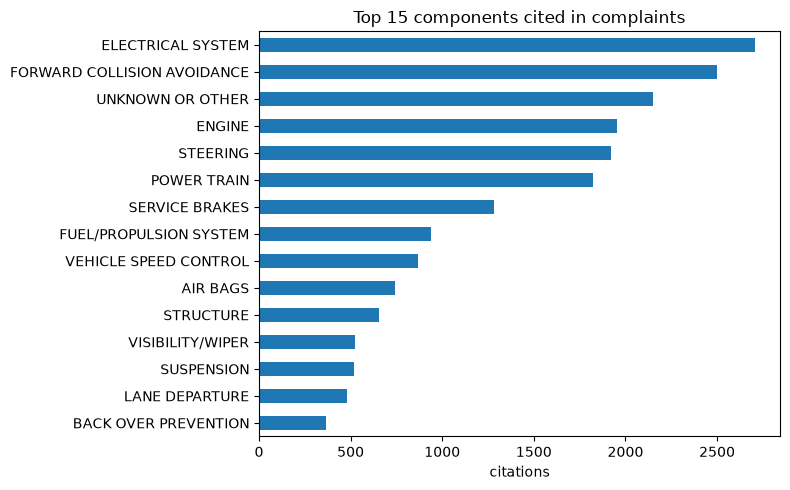

In [5]:
citations = complaints.explode("components")
top_components = citations["components"].value_counts()

print(f"{top_components.size} distinct labels")
ax = top_components.head(15).sort_values().plot.barh(figsize=(8, 5))
ax.set(title="Top 15 components cited in complaints", xlabel="citations", ylabel="")
plt.tight_layout()

In [6]:
labels_per_complaint = complaints["components"].map(len)
labels_per_complaint.value_counts().sort_index().rename("complaints")

components
1    9496
2    3080
3    1930
4       6
Name: complaints, dtype: int64

**Takeaway.** Electrical system, forward collision avoidance (ADAS) and "unknown or other" lead. The label distribution has a long tail (44 labels, some seen fewer than 10 times), and about 35% of complaints carry 2 or more labels: classification is **multi-label and imbalanced**.

## Q2. What is the #1 component for each model?

In [7]:
top_by_model = (
    citations.groupby("model")["components"]
    .value_counts()
    .groupby(level="model")
    .head(3)
    .rename("citations")
)
top_by_model

model           components                 
1500            ELECTRICAL SYSTEM              1030
                ENGINE                          975
                UNKNOWN OR OTHER                600
camry           POWER TRAIN                     181
                AIR BAGS                        167
                UNKNOWN OR OTHER                163
cr-v            STEERING                        831
                FORWARD COLLISION AVOIDANCE     545
                ELECTRICAL SYSTEM               288
explorer        POWER TRAIN                     747
                UNKNOWN OR OTHER                436
                ELECTRICAL SYSTEM               309
grand cherokee  ELECTRICAL SYSTEM               626
                ENGINE                          335
                UNKNOWN OR OTHER                305
model 3         FORWARD COLLISION AVOIDANCE    1457
                VEHICLE SPEED CONTROL           506
                SERVICE BRAKES                  459
Name: citations, dty

**Takeaway.** Each model has its own defect profile: ADAS (forward collision avoidance, i.e. phantom braking) for the Tesla Model 3, steering for the Honda CR-V, power train for the Ford Explorer and Toyota Camry, electrical system for the Stellantis models (Jeep Grand Cherokee, Ram 1500). This is exactly what the agent's "summarise recurring defects for a model" tool must surface.

## Q3. How noisy are the labels?

In [8]:
is_unknown = complaints["components"].map(lambda labels: "UNKNOWN OR OTHER" in labels)
print(f"UNKNOWN OR OTHER: {is_unknown.mean():.1%} of complaints")

unknown_only = complaints["components"].map(lambda labels: labels == ["UNKNOWN OR OTHER"])
print(f"UNKNOWN OR OTHER as the only label: {unknown_only.mean():.1%}")

UNKNOWN OR OTHER: 14.8% of complaints
UNKNOWN OR OTHER as the only label: 8.0%


In [9]:
# What do 'unknown' complaints actually say?
for text in complaints.loc[unknown_only, "summary"].sample(3, random_state=0):
    print("-", text[:300], "\n")

- After coming to a complete stop the throttle does not respond when it is time to move off. After pressing the gas pedal the car will not move forward and the motor does not respond as if it is getting any signal to move off. This happens intermittently and the dealership was not able to recreate aft 

- Delaminating paint 

- Multiple codes are showing up while driving. The car has been at a local Honda dealership for over 3 months while waiting on a part associated with an open recall for fuel pump. The dealership cannot determine the root cause of the codes. 



**Takeaway.** About 15% of complaints are labelled "unknown or other" by the person filing them, yet many describe an identifiable component. The ground truth is **self-reported and noisy**: classifier accuracy against it is a lower bound, and the evaluation set (milestone 4) needs a manually checked sample.

## Q4. Which model has the highest share of complaints involving a crash?

The mean of a boolean column is the share of `True` values.

In [10]:
crash_stats = (
    complaints.groupby("model")
    .agg(
        complaints=("crash", "size"),
        crash_rate=("crash", "mean"),
        fire_rate=("fire", "mean"),
    )
    .sort_values("crash_rate", ascending=False)
)
crash_stats.style.format({"crash_rate": "{:.1%}", "fire_rate": "{:.1%}"})

,complaints,crash_rate,fire_rate
model,,,
model 3,2971,9.8%,0.6%
camry,981,8.4%,0.8%
grand cherokee,1820,5.0%,1.1%
1500,3706,4.4%,0.8%
cr-v,2618,3.6%,0.3%
explorer,2416,3.3%,0.8%


**Takeaway, and a trap.** The Tesla Model 3 has the highest crash share (~10%), followed by the Camry. This does **not** mean it is the most dangerous car:
- it is a rate *among complaints*, not among vehicles on the road (no sales or mileage data);
- **selection bias**: who files a complaint, and about what, differs across brands and owner populations;
- small groups are less reliable (Camry: under 1,000 complaints).

Complaints tell us *what* goes wrong, not *how often* relative to fleet size.

## Q5. Which recalls cover the 2021 Jeep Grand Cherokee?

One campaign covers several vehicles, so the cleaning step stored recalls in two tables. Finding the recalls of one vehicle means filtering the link table, then joining the campaign details.

In [11]:
gc_2021 = recall_vehicles[
    (recall_vehicles["model"] == "grand cherokee") & (recall_vehicles["model_year"] == 2021)
]
gc_2021_recalls = gc_2021.merge(recalls, on="campaign_number", how="inner")

print(f"{len(gc_2021_recalls)} recalls")
gc_2021_recalls[["campaign_number", "report_date", "component", "park_it", "over_the_air"]]

12 recalls


,campaign_number,report_date,component,park_it,over_the_air
0,21V729000,2021-09-21,VISIBILITY:REARVIEW MIRRORS/DEVICES,False,False
1,21V797000,2021-10-14,EXTERIOR LIGHTING:HEADLIGHTS,False,False
2,21V873000,2021-11-10,AIR BAGS: AIR BAG/RESTRAINT CONTROL MODULE:SOF...,False,False
3,21V950000,2021-12-09,EXTERIOR LIGHTING:LIGHTING CONTROL MODULE:SOFT...,False,False
4,22V180000,2022-03-24,CHILD SEAT:VEHICLE TETHER ANCHOR,False,False
5,22V284000,2022-04-28,ENGINE AND ENGINE COOLING:EXHAUST SYSTEM:EMISS...,False,False
6,22V544000,2022-07-28,EXTERIOR LIGHTING:TAIL LIGHTS,False,False
7,23V352000,2023-05-18,STEERING:COLUMN,False,False
8,23V413000,2023-06-08,SUSPENSION:REAR:SPRINGS:COIL SPRINGS,False,False
9,23V577000,2023-08-14,BACK OVER PREVENTION:DISPLAY FUNCTION,False,False


In [12]:
recalls_per_model = recall_vehicles.groupby("model")["campaign_number"].nunique()
recalls_per_model.sort_values(ascending=False).rename("campaigns")

model
1500              56
explorer          49
grand cherokee    36
model 3           31
cr-v              14
camry             10
Name: campaigns, dtype: int64

**Takeaway.** The 2021 Grand Cherokee has 12 recall campaigns. Over 2019-2023, the Ram 1500 and the Ford Explorer have the most campaigns. This join is what the agent's "find related recalls" tool will run.

## Bonus. How long are complaint texts?

count    14512.0
mean       107.0
std         78.0
min          1.0
50%         88.0
90%        220.0
99%        355.0
max        560.0
Name: summary, dtype: float64


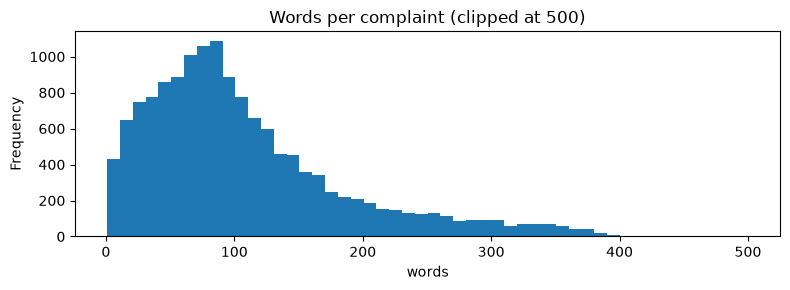

In [13]:
words = complaints["summary"].str.split().str.len()
print(words.describe(percentiles=[0.5, 0.9, 0.99]).round(0))
ax = words.clip(upper=500).plot.hist(bins=50, figsize=(8, 3))
ax.set(title="Words per complaint (clipped at 500)", xlabel="words")
plt.tight_layout()

## Implications for the next milestones

- **RAG (M3)**: complaints are short (median ~90 words, 99th percentile a few hundred), so one complaint = one chunk; no need to split texts. Make, model, year and components become **metadata filters** for retrieval.
- **Evaluation (M4)**: labels are self-reported and ~15% "unknown"; build a small, manually checked test set instead of trusting NHTSA labels blindly.
- **Classifier (M5)**: multi-label, 44 imbalanced raw labels; group them into ~10 classes and use per-class metrics (macro F1), not plain accuracy.
- **Agent (M5)**: per-model defect profiles (Q2) and the recall join (Q5) map directly to the agent's tools.